# Лабораторная работа №10: Эффективный fine-tuning VLM с помощью Unsloth

**Версия:** студенческая  
**Курс:** «Современное компьютерное зрение»

> Сначала выполните notebook в режиме `FAST_DEV_RUN=True`, затем запускайте полный эксперимент. Сохраняйте метрики и checkpoints в `artifacts/`.

## Цели обучения

После работы студент должен уметь:

- Повторить SFT на том же датасете через Unsloth.
- Сравнить LoRA rank и accumulation короткими runs.
- Построить quality-time-memory benchmark.


## Теоретическая часть

Эта работа оценивает не новый task, а efficiency: wall-clock, peak VRAM, throughput и качество при близких hyperparameters. Ускорение без эквивалентного evaluation не является результатом.


**Parameter-Efficient Fine-Tuning** - способ снизить затраты на обучение, при котором обучается лишь небольшая часть параметров или добавляются компактные обучаемые компоненты.

**LoRA (Low-Rank Adaptation)** - добавление к отдельным весовым матрицам модели обучаемые низкоранговые матрицы. Основные параметры исходной модели при этом обычно остаются замороженными, а обучение выполняется преимущественно для адаптеров.

**Ранг** - размер низкорангового представления. Более высокий ранг позволяет адаптеру описывать более сложные изменения, но может увеличивать количество обучаемых параметров и расход памяти.

**Unsloth** — инструмент для более эффективного обучения и дообучения языковых и некоторых мультимодальных моделей. Он позволяет использовать оптимизированные реализации обучения и уменьшать вычислительные затраты в поддерживаемых конфигурациях.

### Математическая постановка

Throughput $=N_{tokens}/T$, peak memory берётся из `torch.cuda.max_memory_allocated()`. Полезно строить Pareto frontier по quality, time и memory.


### Материалы

- [Unsloth docs](https://docs.unsloth.ai/)
- [PEFT](https://huggingface.co/docs/peft/index)

Ссылки даны как дополнительный материал. При изменении API сверяйтесь с актуальной официальной документацией и фиксируйте версии зависимостей.


## Практический протокол

Тот же manifest и та же Qwen2.5-VL, что в работе 9. В Colab требуется совместимая пара версий Unsloth и TRL; зафиксируйте версии и аппаратное обеспечение. `FAST_DEV_RUN=True` всё равно запускает обучение, но только для smoke. Отсутствующие данные или GPU приводят к явной ошибке, а не к демонстрационному benchmark.

In [14]:
from pathlib import Path
import json, os, random, time
import numpy as np
SEED = 66
FAST_DEV_RUN = False  # True: проверка механики на малой выборке, НЕ отчётный эксперимент
ARTIFACTS = Path('artifacts'); ARTIFACTS.mkdir(exist_ok=True)
random.seed(SEED); np.random.seed(SEED)
def save_json(name, data):
    (ARTIFACTS/name).write_text(json.dumps(data, ensure_ascii=False, indent=2, default=str))
from pathlib import Path
import json, hashlib
from datasets import load_dataset

SCIENCEQA_ID = 'derek-thomas/ScienceQA'
SCIENCEQA_REVISION = 'f18b0a70359ebfb41f658fd564208d0355b013f4'

def prepare_scienceqa(directory, smoke=False):
    """Fixed official splits, image-level deduplication, explicitly defined shifts."""
    directory = Path(directory).resolve(); directory.mkdir(parents=True, exist_ok=True)
    manifest = directory / ('manifest-smoke.jsonl' if smoke else 'manifest.jsonl')
    limits = {'train': 8 if smoke else 512, 'validation': 4 if smoke else 64,
              'id_test': 4 if smoke else 64, 'ood_test': 4 if smoke else 64,
              'general_test': 4 if smoke else 64}
    if manifest.exists():
        records = [json.loads(s) for s in manifest.read_text().splitlines()]
        if all(Path(r['image']).is_file() for r in records) and all(sum(r['split']==s for r in records)==n for s,n in limits.items()):
            return manifest
    records, seen, counts = [], set(), dict.fromkeys(limits, 0)
    for official in ('train', 'validation', 'test'):
        data = load_dataset(SCIENCEQA_ID, revision=SCIENCEQA_REVISION, split=official, streaming=True)
        for index, row in enumerate(data):
            image = row['image']
            if image is None: continue
            if official != 'test':
                if row['subject'] != 'natural science' or int(row['grade'].removeprefix('grade')) > 6: continue
                split = official
            elif row['subject'] != 'natural science': split = 'general_test'
            elif int(row['grade'].removeprefix('grade')) > 6: split = 'ood_test'
            else: split = 'id_test'
            if counts[split] >= limits[split]: continue
            image = image.convert('RGB')
            digest = hashlib.sha256(str(image.size).encode()+image.tobytes()).hexdigest()
            if digest in seen: continue
            seen.add(digest)
            path = directory / f'{digest}.png'; image.save(path)
            answer = int(row['answer']); choices = row['choices']
            question = row['question']+'\n'+'\n'.join(f'{chr(65+i)}. {v}' for i,v in enumerate(choices))+'\nReturn only the letter of the correct option.'
            records.append({'id': f'scienceqa-{official}-{index}', 'split': split,
                            'image': str(path), 'question': question, 'answer': chr(65+answer),
                            'choices': choices, 'answer_index': answer, 'label_type': 'multiple_choice',
                            'license': 'MIT (code license, lupantech/ScienceQA)',
                            'source_url': f'https://huggingface.co/datasets/{SCIENCEQA_ID}/tree/{SCIENCEQA_REVISION}',
                            'subject':row['subject'], 'grade':row['grade'], 'image_sha256':digest})
            counts[split] += 1
            required = [official] if official != 'test' else ['id_test','ood_test','general_test']
            if all(counts[s] == limits[s] for s in required): break
    if counts != limits: raise RuntimeError(f'Insufficient licensed image examples: {counts}; expected {limits}')
    manifest.write_text('\n'.join(json.dumps(r,ensure_ascii=False) for r in records)+'\n')
    (directory/'ATTRIBUTION.md').write_text('ScienceQA — Lu et al., NeurIPS 2022. Dataset distribution: '+SCIENCEQA_ID+'\nRevision: '+SCIENCEQA_REVISION+'\nDataset-card license: CC-BY-SA-4.0, https://creativecommons.org/licenses/by-sa/4.0/\nOriginal project: https://scienceqa.github.io/\nImage subsets and manifests retain attribution; downloaded images are not committed to this course.\nID: natural science grades 1–6; OOD: natural science grades 7–12; general: other subjects. This is an operational shift, not a claim of universal model ability.\n')
    return manifest


## Оценивание

Десять обязательных предметных этапов — по 1 баллу каждый, всего 10 баллов. Отдельное творческое исследование — до 1 дополнительного балла. Каждый этап принимается по указанному наблюдаемому результату.

### Одинаковые данные для сравнения

*Вес: 1 балл.*

**Постановка.** Загрузите ту же фиксированную ScienceQA-подвыборку через prepare_scienceqa, что в работе 09. Для сравнения библиотек нельзя менять наборы, вопросы или разбиения.

**Результат.** Манифест и изображения.

**Критерий принятия.** ID/хеши записей совпадают с протоколом 09; train и test не пересекаются.


In [15]:
# Библиотеки

import rarfile
import torch
import inspect

from PIL import Image
from datasets import Dataset
from transformers import set_seed
from trl import SFTTrainer, SFTConfig
from unsloth import FastVisionModel
from unsloth.trainer import UnslothVisionDataCollator

In [4]:
%pip install trl unsloth

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.8/79.8 kB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.0/31.0 MB 72.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 945.8/945.8 kB 66.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 20.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.8/73.8 kB 8.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.3/12.3 MB 88.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.8/2.8 MB 80.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 114.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 116.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 216.9/216.9 kB 20.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 135.1/135.1 kB 13.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 94.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 230.5/23

In [5]:
%pip install rarfile

In [16]:
DATA_DIR = Path("data")
EXTRACT_DIR = DATA_DIR / "lab9"

# Распаковываем архив, если он ещё не распакован
if not EXTRACT_DIR.exists():
    EXTRACT_DIR.mkdir(parents=True)
    with rarfile.RarFile(DATA_DIR / "lab9.rar") as archive:
        archive.extractall(EXTRACT_DIR)

# Ищем манифест из лабораторной №9
manifests = list(EXTRACT_DIR.rglob("manifest*.jsonl"))
if not manifests:
    raise FileNotFoundError(
        "В архиве не найден manifest*.jsonl. Проверьте структуру lab9.rar."
    )

manifest = next(
    (p for p in manifests if p.name == "manifest-smoke.jsonl")
    if FAST_DEV_RUN else
    (p for p in manifests if p.name == "manifest.jsonl"),
    None
) if False else None

# Выбираем smoke-манифест для быстрого запуска, если он есть
preferred_name = "manifest-smoke.jsonl" if FAST_DEV_RUN else "manifest.jsonl"
manifest = next((p for p in manifests if p.name == preferred_name), manifests[0])

records = [json.loads(line) for line in manifest.read_text().splitlines() if line.strip()]

# Восстанавливаем пути к изображениям, если они изменились после распаковки
for record in records:
    image_path = Path(record["image"])
    if not image_path.is_file():
        matches = list(EXTRACT_DIR.rglob(image_path.name))
        if matches:
            record["image"] = str(matches[0].resolve())
        else:
            raise FileNotFoundError(f"Не найдено изображение: {image_path.name}")

# Проверяем пересечения по ID и хешу изображений между train и тестом
train = [r for r in records if r["split"] == "train"]
test = [r for r in records if r["split"] in ("id_test", "ood_test", "general_test", "test")]

train_ids = {r["id"] for r in train}
test_ids = {r["id"] for r in test}
train_hashes = {r.get("image_sha256") for r in train if r.get("image_sha256")}
test_hashes = {r.get("image_sha256") for r in test if r.get("image_sha256")}

assert not train_ids & test_ids, "Train/test пересекаются по ID"
assert not train_hashes & test_hashes, "Train/test пересекаются по хешам изображений"

# Сохраняем используемый манифест в artifacts
output_manifest = ARTIFACTS / "manifest.jsonl"
output_manifest.write_text(
    "\n".join(json.dumps(r, ensure_ascii=False) for r in records) + "\n"
)

print(f"Манифест: {output_manifest}")
print(f"Train: {len(train)}, test: {len(test)}")

Манифест: artifacts/manifest.jsonl
Train: 512, test: 192


### Равный вычислительный бюджет

*Вес: 1 балл.*

**Постановка.** Зафиксируйте Qwen2.5-VL-3B-Instruct, GPU, 100 optimizer steps и accumulation 16. Сравнивайте ранги 8 и 16 при одинаковом количестве обработанных примеров.

**Результат.** protocol.json.

**Критерий принятия.** Сохранены GPU, модель, размеры выборок и бюджет; для обеих серий указан один seed.


In [17]:
MODEL_NAME = "Qwen/Qwen2.5-VL-3B-Instruct"

records = [
    json.loads(line)
    for line in (ARTIFACTS / "manifest.jsonl").read_text().splitlines()
    if line.strip()
]

counts = {}
for split in ("train", "validation", "id_test", "ood_test", "general_test"):
    counts[split] = sum(r["split"] == split for r in records)

protocol = {
    "model": MODEL_NAME,
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
    "seed": SEED,
    "fast_dev_run": FAST_DEV_RUN,
    "optimizer_steps": 2 if FAST_DEV_RUN else 100,
    "gradient_accumulation_steps": 16,
    "lora_ranks": [8, 16],
    "train_samples": counts["train"],
    "validation_samples": counts["validation"],
    "id_test_samples": counts["id_test"],
    "ood_test_samples": counts["ood_test"],
    "general_test_samples": counts["general_test"],
    "split_sizes": counts,
}

(ARTIFACTS / "protocol.json").write_text(
    json.dumps(protocol, ensure_ascii=False, indent=2)
)

print(json.dumps(protocol, ensure_ascii=False, indent=2))

{
  "model": "Qwen/Qwen2.5-VL-3B-Instruct",
  "gpu": "Tesla T4",
  "seed": 66,
  "fast_dev_run": false,
  "optimizer_steps": 100,
  "gradient_accumulation_steps": 16,
  "lora_ranks": [
    8,
    16
  ],
  "train_samples": 512,
  "validation_samples": 64,
  "id_test_samples": 64,
  "ood_test_samples": 64,
  "general_test_samples": 64,
  "split_sizes": {
    "train": 512,
    "validation": 64,
    "id_test": 64,
    "ood_test": 64,
    "general_test": 64
  }
}


### Цикл мультимодального SFT

*Вес: 1 балл.*

**Постановка.** Реализуйте train_adapter с UnslothVisionDataCollator, AdamW, накоплением градиентов и ограничением их нормы. Измеряйте время с CUDA synchronize, сохраняйте историю loss и обученный адаптер.

**Результат.** Функция train_adapter.

**Критерий принятия.** На каждый optimizer step приходится accumulation микробатчей; измерения реальны; нечисловой loss вызывает ошибку.


In [18]:
protocol = json.loads((ARTIFACTS / "protocol.json").read_text())
records = [
    json.loads(line)
    for line in (ARTIFACTS / "manifest.jsonl").read_text().splitlines()
    if line.strip()
]

def train_adapter(model, tokenizer, rank, alpha, output_dir):
    set_seed(protocol["seed"])
    random.seed(protocol["seed"])
    np.random.seed(protocol["seed"])

    # Формат диалога для мультимодального SFT: изображение + вопрос -> ответ
    rows = []
    for r in records:
        if r["split"] != "train":
            continue
        with Image.open(r["image"]) as img:
            image = img.convert("RGB").copy()
        rows.append({
            "messages": [
                {"role": "user", "content": [
                    {"type": "image", "image": image},
                    {"type": "text", "text": r["question"]}
                ]},
                {"role": "assistant", "content": [
                    {"type": "text", "text": r["answer"]}
                ]}
            ]
        })

    dataset = Dataset.from_list(rows)
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)

    args_dict = {
        "output_dir": str(output_dir / "trainer"),
        "max_steps": protocol["optimizer_steps"],
        "per_device_train_batch_size": 1,
        "gradient_accumulation_steps": protocol["gradient_accumulation_steps"],
        "learning_rate": 2e-4,
        "warmup_steps": 0,
        "logging_steps": 1,
        "optim": "adamw_torch",
        "max_grad_norm": 0.3,
        "weight_decay": 0.01,
        "lr_scheduler_type": "linear",
        "seed": protocol["seed"],
        "report_to": "none",
        "remove_unused_columns": False,
        "fp16": False,
        "bf16": False,
    }

    # Название параметра длины зависит от версии TRL
    config_params = inspect.signature(SFTConfig.__init__).parameters
    if "max_seq_length" in config_params:
        args_dict["max_seq_length"] = 2048
    elif "max_length" in config_params:
        args_dict["max_length"] = 2048

    if "dataset_kwargs" in config_params:
        args_dict["dataset_kwargs"] = {"skip_prepare_dataset": True}
    if "dataset_text_field" in config_params:
        args_dict["dataset_text_field"] = ""

    trainer_params = inspect.signature(SFTTrainer.__init__).parameters
    trainer_kwargs = {
        "model": model,
        "train_dataset": dataset,
        "data_collator": UnslothVisionDataCollator(model, tokenizer),
        "args": SFTConfig(**args_dict),
    }
    if "processing_class" in trainer_params:
        trainer_kwargs["processing_class"] = tokenizer
    else:
        trainer_kwargs["tokenizer"] = tokenizer

    trainer = SFTTrainer(**trainer_kwargs)

    if torch.cuda.is_available():
        torch.cuda.synchronize()
        torch.cuda.reset_peak_memory_stats()

    start = time.perf_counter()
    trainer.train()
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    elapsed = time.perf_counter() - start

    peak_vram_gb = (
        torch.cuda.max_memory_allocated() / 1024**3
        if torch.cuda.is_available() else None
    )

    history = [
        {"step": item["step"], "loss": item["loss"]}
        for item in trainer.state.log_history
        if "loss" in item and np.isfinite(item["loss"])
    ]

    # Проверяем, что все записанные значения loss конечны
    if not history or any(not np.isfinite(item["loss"]) for item in history):
        raise ValueError("Loss отсутствует или содержит NaN/Inf")

    adapter_dir = output_dir / "adapter"
    trainer.model.save_pretrained(adapter_dir)
    tokenizer.save_pretrained(adapter_dir)

    result = {
        "rank": rank,
        "alpha": alpha,
        "seed": protocol["seed"],
        "optimizer_steps_requested": protocol["optimizer_steps"],
        "optimizer_steps_completed": trainer.state.global_step,
        "gradient_accumulation_steps": protocol["gradient_accumulation_steps"],
        "micro_batch_size": 1,
        "train_samples": len(dataset),
        "elapsed_seconds": elapsed,
        "peak_cuda_memory_gb": peak_vram_gb,
        "loss_history": history,
        "adapter_dir": str(adapter_dir),
    }
    (output_dir / "training.json").write_text(
        json.dumps(result, ensure_ascii=False, indent=2)
    )

    if trainer.state.global_step != protocol["optimizer_steps"]:
        raise RuntimeError("Выполнено не ожидаемое число optimizer steps")

    return result

### LoRA ранга 8

*Вес: 1 балл.*

**Постановка.** Создайте FastVisionModel и LoRA rank 8, alpha 16. Обучите модель по общему протоколу и сохраните адаптер отдельно.

**Результат.** unsloth_r8_a16/adapter и training.json.

**Критерий принятия.** Фактически выполнено 100 optimizer steps; зафиксированы loss, время и пиковая CUDA-память.


In [19]:

MODEL_NAME = protocol["model"]

model, tokenizer = FastVisionModel.from_pretrained(
    model_name=MODEL_NAME,
    load_in_4bit=True,
    dtype=torch.float16,
    use_gradient_checkpointing="unsloth",
)

model = FastVisionModel.get_peft_model(
    model,
    r=8,
    lora_alpha=16,
    lora_dropout=0,
    bias="none",
    finetune_vision_layers=True,
    finetune_language_layers=True,
    finetune_attention_modules=True,
    finetune_mlp_modules=True,
    use_gradient_checkpointing="unsloth",
    random_state=protocol["seed"],
    # dtype=torch.float16 убираем
)

# Обучаемые параметры LoRA оставляем в FP32
for param in model.parameters():
    if param.requires_grad:
        param.data = param.data.to(torch.float32)

from collections import Counter

print("Trainable parameter dtypes:")
print(Counter(
    str(p.dtype) for p in model.parameters()
    if p.requires_grad
))

FastVisionModel.for_training(model)

result_r8 = train_adapter(
    model,
    tokenizer,
    rank=8,
    alpha=16,
    output_dir="unsloth_r8_a16",
)

print(json.dumps(result_r8, ensure_ascii=False, indent=2))


==((====))==  Unsloth 2026.10.7: Fast Qwen2_5_Vl patching. Transformers: 5.17.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading weights:   0%|          | 0/824 [00:00<?, ?it/s]

Skipping model.language_model.layers.1.mlp.gate_proj: no quant_state found
Skipping model.language_model.layers.1.mlp.up_proj: no quant_state found
Skipping model.language_model.layers.1.mlp.down_proj: no quant_state found
Skipping model.language_model.layers.2.mlp.gate_proj: no quant_state found
Skipping model.language_model.layers.2.mlp.up_proj: no quant_state found
Skipping model.language_model.layers.2.mlp.down_proj: no quant_state found
Skipping model.language_model.layers.5.mlp.gate_proj: no quant_state found
Skipping model.language_model.layers.5.mlp.up_proj: no quant_state found
Skipping model.language_model.layers.5.mlp.down_proj: no quant_state found
Skipping model.language_model.layers.30.mlp.gate_proj: no quant_state found
Skipping model.language_model.layers.30.mlp.up_proj: no quant_state found
Skipping model.language_model.layers.30.mlp.down_proj: no quant_state found
Trainable parameter dtypes:
Counter({'torch.float32': 824})
Unsloth: Model does not have a default image 

The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': 151645, 'bos_token_id': None}.
==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 512 | Num Epochs = 4 | Total steps = 100
O^O/ \_/ \    Batch size per device = 1 | Gradient accumulation steps = 16
\        /    Data Parallel GPUs = 1 | Total batch size (1 x 16 x 1) = 16
 "-____-"     Trainable parameters = 20,542,464 of 3,775,165,440 (0.54% trained)


Step,Training Loss
1,6.128785
2,5.452467
3,3.940014
4,3.037718
5,2.397313
6,2.178702
7,2.049736
8,1.789007
9,1.850260
10,1.669525


Unsloth: Restored added_tokens_decoder metadata in unsloth_r8_a16/trainer/checkpoint-100/tokenizer_config.json.
Unsloth: Restored added_tokens_decoder metadata in unsloth_r8_a16/adapter/tokenizer_config.json.


{
  "rank": 8,
  "alpha": 16,
  "seed": 66,
  "optimizer_steps_requested": 100,
  "optimizer_steps_completed": 100,
  "gradient_accumulation_steps": 16,
  "micro_batch_size": 1,
  "train_samples": 512,
  "elapsed_seconds": 1319.577214624,
  "peak_cuda_memory_gb": 8.028652667999268,
  "loss_history": [
    {
      "step": 1,
      "loss": 6.128784656524658
    },
    {
      "step": 2,
      "loss": 5.452467441558838
    },
    {
      "step": 3,
      "loss": 3.940014123916626
    },
    {
      "step": 4,
      "loss": 3.037717819213867
    },
    {
      "step": 5,
      "loss": 2.397313356399536
    },
    {
      "step": 6,
      "loss": 2.1787021160125732
    },
    {
      "step": 7,
      "loss": 2.049736499786377
    },
    {
      "step": 8,
      "loss": 1.7890069484710693
    },
    {
      "step": 9,
      "loss": 1.8502603769302368
    },
    {
      "step": 10,
      "loss": 1.669525146484375
    },
    {
      "step": 11,
      "loss": 1.6366970539093018
    },
    {
   

### LoRA ранга 16

*Вес: 1 балл.*

**Постановка.** Повторите эксперимент с rank 16, alpha 32. Начинайте с исходной модели, а не с адаптера ранга 8.

**Результат.** unsloth_r16_a16/adapter и training.json.

**Критерий принятия.** Меняется только ранг и соответствующий alpha; порядок данных, число шагов и effective batch совпадают.


In [20]:
model, tokenizer = FastVisionModel.from_pretrained(
    model_name=protocol["model"],
    load_in_4bit=True,
    dtype=torch.float16,
    use_gradient_checkpointing="unsloth",
)

model = FastVisionModel.get_peft_model(
    model,
    r=16,
    lora_alpha=32,
    lora_dropout=0,
    bias="none",
    finetune_vision_layers=True,
    finetune_language_layers=True,
    finetune_attention_modules=True,
    finetune_mlp_modules=True,
    use_gradient_checkpointing="unsloth",
    random_state=protocol["seed"],
    dtype=torch.float16,
)

# Обучаемые параметры LoRA оставляем в FP32
for param in model.parameters():
    if param.requires_grad:
        param.data = param.data.to(torch.float32)

from collections import Counter

print("Trainable parameter dtypes:")
print(Counter(
    str(p.dtype) for p in model.parameters()
    if p.requires_grad
))

FastVisionModel.for_training(model)

result_r16 = train_adapter(
    model, tokenizer,
    rank=16, alpha=32,
    output_dir="unsloth_r16_a16",
)

print(json.dumps(result_r16, ensure_ascii=False, indent=2))

==((====))==  Unsloth 2026.10.7: Fast Qwen2_5_Vl patching. Transformers: 5.17.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading weights:   0%|          | 0/824 [00:00<?, ?it/s]

Skipping model.language_model.layers.1.mlp.gate_proj: no quant_state found
Skipping model.language_model.layers.1.mlp.up_proj: no quant_state found
Skipping model.language_model.layers.1.mlp.down_proj: no quant_state found
Skipping model.language_model.layers.2.mlp.gate_proj: no quant_state found
Skipping model.language_model.layers.2.mlp.up_proj: no quant_state found
Skipping model.language_model.layers.2.mlp.down_proj: no quant_state found
Skipping model.language_model.layers.5.mlp.gate_proj: no quant_state found
Skipping model.language_model.layers.5.mlp.up_proj: no quant_state found
Skipping model.language_model.layers.5.mlp.down_proj: no quant_state found
Skipping model.language_model.layers.30.mlp.gate_proj: no quant_state found
Skipping model.language_model.layers.30.mlp.up_proj: no quant_state found
Skipping model.language_model.layers.30.mlp.down_proj: no quant_state found
Trainable parameter dtypes:
Counter({'torch.float32': 824})
Unsloth: Model does not have a default image 

The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': 151645, 'bos_token_id': None}.
==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 512 | Num Epochs = 4 | Total steps = 100
O^O/ \_/ \    Batch size per device = 1 | Gradient accumulation steps = 16
\        /    Data Parallel GPUs = 1 | Total batch size (1 x 16 x 1) = 16
 "-____-"     Trainable parameters = 41,084,928 of 3,795,707,904 (1.08% trained)


Step,Training Loss
1,6.128785
2,4.567669
3,4.232268
4,2.699548
5,2.712157
6,2.193610
7,1.970035
8,1.512630
9,1.347353
10,0.989893


Unsloth: Double buffering enabled (parallel H2D + compute) for backward pass.
Unsloth: Will smartly offload gradients to save VRAM!


Unsloth: Restored added_tokens_decoder metadata in unsloth_r16_a16/trainer/checkpoint-100/tokenizer_config.json.
Unsloth: Restored added_tokens_decoder metadata in unsloth_r16_a16/adapter/tokenizer_config.json.


{
  "rank": 16,
  "alpha": 32,
  "seed": 66,
  "optimizer_steps_requested": 100,
  "optimizer_steps_completed": 100,
  "gradient_accumulation_steps": 16,
  "micro_batch_size": 1,
  "train_samples": 512,
  "elapsed_seconds": 1254.3199350359996,
  "peak_cuda_memory_gb": 8.350664615631104,
  "loss_history": [
    {
      "step": 1,
      "loss": 6.128784656524658
    },
    {
      "step": 2,
      "loss": 4.56766939163208
    },
    {
      "step": 3,
      "loss": 4.232268333435059
    },
    {
      "step": 4,
      "loss": 2.699547529220581
    },
    {
      "step": 5,
      "loss": 2.7121572494506836
    },
    {
      "step": 6,
      "loss": 2.1936097145080566
    },
    {
      "step": 7,
      "loss": 1.9700349569320679
    },
    {
      "step": 8,
      "loss": 1.5126299858093262
    },
    {
      "step": 9,
      "loss": 1.3473528623580933
    },
    {
      "step": 10,
      "loss": 0.9898934364318848
    },
    {
      "step": 11,
      "loss": 0.9171016812324524
    },
  

### Траектории оптимизации

*Вес: 1 балл.*

**Постановка.** Постройте график loss по optimizer steps для двух рангов. Сопоставьте число шагов, время и пиковую память, прежде чем делать вывод о полезности большего ранга.

**Результат.** loss_comparison.png и benchmark.json.

**Критерий принятия.** График построен по реальным историям обучения, оси и ранги подписаны; отсутствующие измерения не заменены константой.


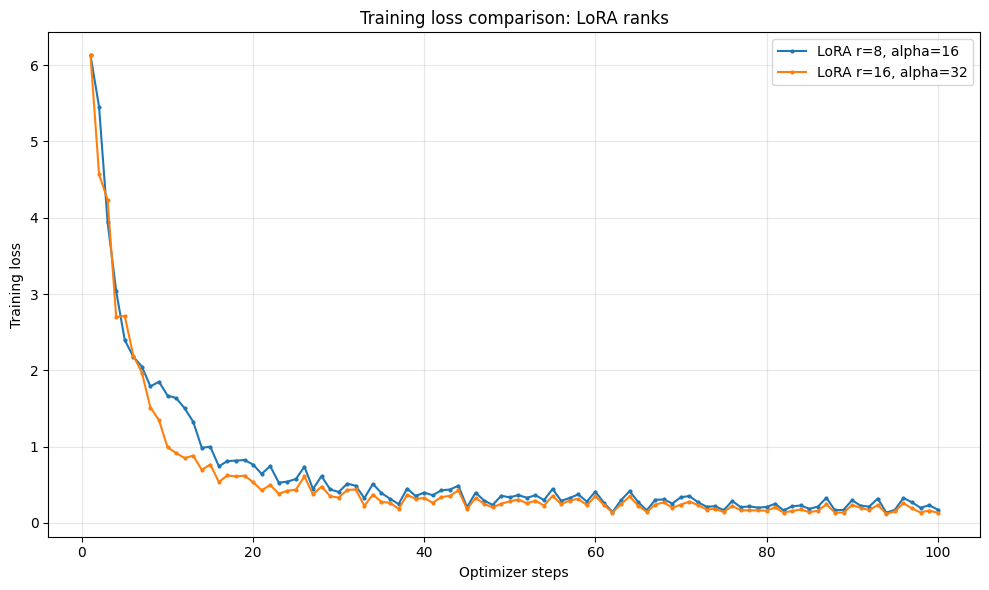

rank=8, alpha=16, steps=100, time=1319.58 s, peak VRAM=8.028652667999268 GB
rank=16, alpha=32, steps=100, time=1254.32 s, peak VRAM=8.350664615631104 GB

График: artifacts/loss_comparison.png
Бенчмарк: artifacts/benchmark.json


In [21]:
import matplotlib.pyplot as plt

# Читаем результаты именно завершённых экспериментов.
# Если файла нет, не подменяем результаты.
runs = []
for rank, alpha, run_dir in [
    (8, 16, Path("unsloth_r8_a16")),
    (16, 32, Path("unsloth_r16_a16")),
]:
    result_path = run_dir / "training.json"
    adapter_path = run_dir / "adapter"

    if not result_path.is_file():
        raise FileNotFoundError(
            f"Не найден {result_path}. "
            "Сначала успешно обучи соответствующий адаптер."
        )

    if not adapter_path.is_dir():
        raise FileNotFoundError(
            f"Не найден адаптер: {adapter_path}"
        )

    result = json.loads(result_path.read_text())

    if result.get("rank") != rank or result.get("alpha") != alpha:
        raise ValueError(
            f"Конфигурация в {result_path} не совпадает "
            f"с ожидаемой: rank={rank}, alpha={alpha}"
        )

    history = result.get("loss_history", [])
    if not history:
        raise ValueError(f"В {result_path} отсутствует история loss.")

    steps = [item["step"] for item in history]
    losses = [item["loss"] for item in history]

    if (
        len(steps) != len(losses)
        or not np.isfinite(losses).all()
        or any(s < 1 for s in steps)
    ):
        raise ValueError(f"Некорректная история loss в {result_path}.")

    if result.get("optimizer_steps_completed", 0) <= 0:
        raise ValueError(f"В {result_path} нет завершённых шагов.")

    runs.append(result)

# График по фактическим значениям trainer.state.log_history.
fig, ax = plt.subplots(figsize=(10, 6))

for result in runs:
    history = result["loss_history"]
    steps = [item["step"] for item in history]
    losses = [item["loss"] for item in history]

    ax.plot(
        steps,
        losses,
        marker=".",
        markersize=4,
        linewidth=1.5,
        label=f"LoRA r={result['rank']}, alpha={result['alpha']}",
    )

ax.set_xlabel("Optimizer steps")
ax.set_ylabel("Training loss")
ax.set_title("Training loss comparison: LoRA ranks")
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()

plot_path = ARTIFACTS / "loss_comparison.png"
fig.savefig(plot_path, dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

# Сохраняем измерения.
benchmark = {
    "model": protocol["model"],
    "seed": protocol["seed"],
    "gpu": protocol.get("gpu"),
    "fast_dev_run": protocol["fast_dev_run"],
    "gradient_accumulation_steps": protocol["gradient_accumulation_steps"],
    "runs": runs,
}

benchmark_path = ARTIFACTS / "benchmark.json"
benchmark_path.write_text(
    json.dumps(benchmark, ensure_ascii=False, indent=2, allow_nan=False)
)

# Краткая таблица фактических измерений.
for result in runs:
    print(
        f"rank={result['rank']}, alpha={result['alpha']}, "
        f"steps={result['optimizer_steps_completed']}, "
        f"time={result['elapsed_seconds']:.2f} s, "
        f"peak VRAM={result['peak_cuda_memory_gb']} GB"
    )

print(f"\nГрафик: {plot_path}")
print(f"Бенчмарк: {benchmark_path}")


### Общий интерфейс инференса

*Вес: 1 балл.*

**Постановка.** Реализуйте один greedy-инференс для обоих адаптеров: общие processor, размер изображения, max_new_tokens и извлечение продолжения.

**Результат.** Функция infer.

**Критерий принятия.** Выход не содержит prompt; ответы получаются от активного адаптера на реальном изображении.


In [22]:
from PIL import Image, ImageOps
from unsloth import FastVisionModel

# Общие настройки для обоих адаптеров.
MAX_IMAGE_SIZE = (512, 512)
MAX_NEW_TOKENS = 16


def infer(model, processor, image, question, max_new_tokens=MAX_NEW_TOKENS,):
    """
    Генерирует ответ для изображения и вопроса.
    model должен содержать нужный активный LoRA-адаптер.
    processor — объект, возвращённый FastVisionModel.from_pretrained().
    """

    if max_new_tokens < 1:
        raise ValueError("max_new_tokens должен быть положительным.")

    # Принимаем как PIL.Image, так и путь к изображению.
    if isinstance(image, (str, Path)):
        with Image.open(image) as img:
            image = img.convert("RGB").copy()
    elif isinstance(image, Image.Image):
        image = image.convert("RGB")
    else:
        raise TypeError("image должен быть PIL.Image или путём к файлу.")

    # Общий размер обработки, сохраняем пропорции изображения.
    image = ImageOps.contain(image, MAX_IMAGE_SIZE)

    messages = [
        {
            "role": "user",
            "content": [
                {"type": "image", "image": image},
                {"type": "text", "text": question},
            ],
        }
    ]

    # Формируем prompt в формате чата модели.
    prompt = processor.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
    )

    # Процессор формирует токены текста и представление изображения.
    inputs = processor(
        text=[prompt],
        images=[image],
        return_tensors="pt",
    )

    # Переносим входы на устройство модели.
    device = next(model.parameters()).device
    inputs = inputs.to(device)

    # Включаем режим инференса Unsloth.
    FastVisionModel.for_inference(model)
    model.eval()

    with torch.inference_mode():
        output_ids = model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False,
            num_beams=1,
        )

    # Отбрасываем входные токены: декодируем только продолжение.
    input_length = inputs["input_ids"].shape[1]
    generated_ids = output_ids[:, input_length:]

    answer = processor.batch_decode(
        generated_ids,
        skip_special_tokens=True,
        clean_up_tokenization_spaces=False,
    )[0]

    return answer.strip()


### Метрика и ошибки формата

*Вес: 1 балл.*

**Постановка.** Определите exact match правильной буквы и отдельную долю ответов допустимого формата A–Z. Реализуйте подсчёт по split с явными знаменателями; пустая выборка должна вызывать ошибку.

**Результат.** Функция evaluate_answers.

**Критерий принятия.** Верный ответ даёт EM=1, неверный и лишний текст — EM=0; n равен числу всех примеров split.


In [23]:
def evaluate_answers(records, predictions, splits=("id_test", "ood_test")):
    if isinstance(predictions, dict):
        pred_by_id = predictions
    else:
        pred_by_id = {}
        for p in predictions:
            sample_id = p["id"]
            if sample_id in pred_by_id:
                raise ValueError(f"Повторный prediction для id={sample_id}")
            pred_by_id[sample_id] = p.get("raw_text", "")

    result = {
        "metrics": {},
        "per_example": []
    }

    for split in splits:
        split_records = [r for r in records if r["split"] == split]

        if not split_records:
            raise ValueError(f"Split {split!r} пуст: метрики не определены")

        correct = 0
        valid_format = 0
        evaluated = []

        for r in split_records:
            sample_id = r["id"]

            if sample_id not in pred_by_id:
                raise ValueError(
                    f"Нет предсказания для id={sample_id}, split={split}"
                )

            raw_text = pred_by_id[sample_id]
            if not isinstance(raw_text, str):
                raw_text = str(raw_text)

            # Допускается только одна заглавная латинская буква A–Z.
            # strip() убирает внешние пробелы, но не исправляет ответ.
            answer_text = raw_text.strip()
            format_ok = re.fullmatch(r"[A-Z]", answer_text) is not None

            gold = str(r["answer"]).strip()
            exact_match = format_ok and (answer_text == gold)

            valid_format += int(format_ok)
            correct += int(exact_match)

            evaluated.append({
                "id": sample_id,
                "split": split,
                "gold": gold,
                "raw_text": raw_text,
                "format_valid": format_ok,
                "exact_match": int(exact_match)
            })

        n = len(split_records)

        result["metrics"][split] = {
            "n": n,
            "exact_match_correct": correct,
            "exact_match": correct / n,
            "format_valid": valid_format,
            "format_rate": valid_format / n
        }
        result["per_example"].extend(evaluated)

    return result


print("Функция evaluate_answers определена.")

Функция evaluate_answers определена.


### Качество двух адаптеров

*Вес: 1 балл.*

**Постановка.** Примените оба адаптера к одним ID/OOD изображениям и рассчитайте согласованные метрики. Сохраните исходный текст каждого ответа.

**Результат.** predictions_r8_a16.jsonl и predictions_r16_a16.jsonl.

**Критерий принятия.** Наборы ID совпадают между сериями; отчёт содержит exact match, format rate и n на ID/OOD.


In [29]:
import re
import gc
from unsloth import FastVisionModel

ARTIFACTS = Path("artifacts")
MODEL_NAME = protocol["model"]

test_records = [
    r for r in records
    if r["split"] in ("id_test", "ood_test", "general_test")
]

if not test_records:
    raise ValueError("В манифесте отсутствуют ID/OOD/general тестовые примеры.")

ids_by_split = {
    split: {r["id"] for r in test_records if r["split"] == split}
    for split in ("id_test", "ood_test", "general_test")
}

if not ids_by_split["id_test"] or not ids_by_split["ood_test"] or not ids_by_split["general_test"]:
    raise ValueError("ID или OOD или general тестовая выборка пуста.")


def predict_with_adapter(adapter_dir, output_file):
    adapter_dir = Path(adapter_dir)

    if not adapter_dir.is_dir():
        raise FileNotFoundError(
            f"Адаптер не найден: {adapter_dir}. "
            "Сначала выполните обучение соответствующего rank."
        )

    # Загружаем сохранённый адаптер, а не обучаем новую модель.
    model, tokenizer = FastVisionModel.from_pretrained(
        model_name=str(adapter_dir),
        load_in_4bit=True,
        dtype=torch.float16,
        use_gradient_checkpointing="unsloth",
    )
    FastVisionModel.for_inference(model)

    predictions = []

    try:
        for i, r in enumerate(test_records, start=1):
            raw_text = infer(
                model,
                tokenizer,
                r["image"],
                r["question"],
            )

            predictions.append({
                "id": r["id"],
                "split": r["split"],
                "gold": r["answer"],
                "raw_text": raw_text,
                "rank": 8 if "r8" in str(adapter_dir) else 16,
                "image_sha256": r.get("image_sha256"),
            })

            if i % 10 == 0 or i == len(test_records):
                print(
                    f"{adapter_dir}: обработано "
                    f"{i}/{len(test_records)}"
                )
    finally:
        del model, tokenizer
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    output_file = ARTIFACTS / output_file
    with output_file.open("w", encoding="utf-8") as f:
        for p in predictions:
            f.write(json.dumps(p, ensure_ascii=False) + "\n")

    return predictions


predictions_r8 = predict_with_adapter(
    "unsloth_r8_a16/adapter",
    "predictions_r8_a16.jsonl",
)

predictions_r16 = predict_with_adapter(
    "unsloth_r16_a16/adapter",
    "predictions_r16_a16.jsonl",
)

# Проверяем, что обе серии оценивали одинаковые примеры.
ids_r8 = {p["id"] for p in predictions_r8}
ids_r16 = {p["id"] for p in predictions_r16}
expected_ids = {r["id"] for r in test_records}

assert ids_r8 == ids_r16 == expected_ids, (
    "Наборы примеров для адаптеров не совпадают."
)

# Метрики с одинаковыми знаменателями.
metrics_r8 = evaluate_answers(records, predictions_r8)
metrics_r16 = evaluate_answers(records, predictions_r16)

paired_results = {
    "model": MODEL_NAME,
    "seed": protocol["seed"],
    "splits": {},
    "per_example": [],
}

for split in ("id_test", "ood_test"):
    paired_results["splits"][split] = {
        "r8_a16": metrics_r8["metrics"][split],
        "r16_a32": metrics_r16["metrics"][split],
    }

    r8_by_id = {
        p["id"]: p for p in metrics_r8["per_example"]
        if p["split"] == split
    }
    r16_by_id = {
        p["id"]: p for p in metrics_r16["per_example"]
        if p["split"] == split
    }

    for sample_id in sorted(r8_by_id):
        a = r8_by_id[sample_id]
        b = r16_by_id[sample_id]
        paired_results["per_example"].append({
            "id": sample_id,
            "split": split,
            "gold": a["gold"],
            "r8_a16": {
                "raw_text": a["raw_text"],
                "format_valid": a["format_valid"],
                "exact_match": a["exact_match"],
            },
            "r16_a32": {
                "raw_text": b["raw_text"],
                "format_valid": b["format_valid"],
                "exact_match": b["exact_match"],
            },
        })

(ARTIFACTS / "paired_results.json").write_text(
    json.dumps(paired_results, ensure_ascii=False, indent=2)
)

print(json.dumps(paired_results["splits"], ensure_ascii=False, indent=2))
print("Сохранены:")
print(" - artifacts/predictions_r8_a16.jsonl")
print(" - artifacts/predictions_r16_a16.jsonl")
print(" - artifacts/paired_results.json")

==((====))==  Unsloth 2026.10.7: Fast Qwen2_5_Vl patching. Transformers: 5.17.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading weights:   0%|          | 0/824 [00:00<?, ?it/s]

Skipping model.language_model.layers.1.mlp.gate_proj: no quant_state found
Skipping model.language_model.layers.1.mlp.up_proj: no quant_state found
Skipping model.language_model.layers.1.mlp.down_proj: no quant_state found
Skipping model.language_model.layers.2.mlp.gate_proj: no quant_state found
Skipping model.language_model.layers.2.mlp.up_proj: no quant_state found
Skipping model.language_model.layers.2.mlp.down_proj: no quant_state found
Skipping model.language_model.layers.5.mlp.gate_proj: no quant_state found
Skipping model.language_model.layers.5.mlp.up_proj: no quant_state found
Skipping model.language_model.layers.5.mlp.down_proj: no quant_state found
Skipping model.language_model.layers.30.mlp.gate_proj: no quant_state found
Skipping model.language_model.layers.30.mlp.up_proj: no quant_state found
Skipping model.language_model.layers.30.mlp.down_proj: no quant_state found


Both `max_new_tokens` (=16) and `max_length`(=128000) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=16) and `max_length`(=128000) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=16) and `max_length`(=128000) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=16) and `max_length`(=128000) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_gene

unsloth_r8_a16/adapter: обработано 10/192


...

unsloth_r16_a16/adapter: обработано 180/192


Both `max_new_tokens` (=16) and `max_length`(=128000) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=16) and `max_length`(=128000) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=16) and `max_length`(=128000) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=16) and `max_length`(=128000) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_gene

unsloth_r16_a16/adapter: обработано 190/192


Both `max_new_tokens` (=16) and `max_length`(=128000) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


unsloth_r16_a16/adapter: обработано 192/192
{
  "id_test": {
    "r8_a16": {
      "n": 64,
      "exact_match_correct": 53,
      "exact_match": 0.828125,
      "format_valid": 64,
      "format_rate": 1.0
    },
    "r16_a32": {
      "n": 64,
      "exact_match_correct": 54,
      "exact_match": 0.84375,
      "format_valid": 64,
      "format_rate": 1.0
    }
  },
  "ood_test": {
    "r8_a16": {
      "n": 64,
      "exact_match_correct": 39,
      "exact_match": 0.609375,
      "format_valid": 64,
      "format_rate": 1.0
    },
    "r16_a32": {
      "n": 64,
      "exact_match_correct": 45,
      "exact_match": 0.703125,
      "format_valid": 64,
      "format_rate": 1.0
    }
  }
}
Сохранены:
 - artifacts/predictions_r8_a16.jsonl
 - artifacts/predictions_r16_a16.jsonl
 - artifacts/paired_results.json


### Сравнение подходов

*Вес: 1 балл.*

**Постановка.** Сопоставьте качество двух рангов и результат LLaMA-Factory из работы 09. Скорость библиотек сравнивайте только при одинаковых GPU, шагах, effective batch и обучаемых модулях. Отсутствующий baseline обозначьте явно.

**Результат.** comparison.json и вывод.

**Критерий принятия.** Не заявлен speedup по несопоставимым измерениям; отсутствие baseline не выдано за нулевое качество; для полного сравнения приложен результат 09.


In [31]:
import pandas as pd
from IPython.display import display

ARTIFACTS = Path("artifacts")
SPLITS = ("id_test", "ood_test", "general_test")


def read_json(path):
    path = Path(path)
    if not path.exists():
        print(f"Не найден файл: {path}")
        return {}
    with path.open("r", encoding="utf-8") as f:
        return json.load(f)


def read_jsonl(path):
    path = Path(path)
    if not path.exists():
        print(f"Не найден файл: {path}")
        return []
    with path.open("r", encoding="utf-8") as f:
        return [json.loads(line) for line in f if line.strip()]


def find_number(obj, keys):
    """Ищет числовое значение по возможным именам ключа во вложенном JSON."""
    if isinstance(obj, dict):
        for key in keys:
            value = obj.get(key)
            if isinstance(value, (int, float)) and not isinstance(value, bool):
                return float(value)
        for value in obj.values():
            result = find_number(value, keys)
            if result is not None:
                return result
    elif isinstance(obj, list):
        for value in obj:
            result = find_number(value, keys)
            if result is not None:
                return result
    return None


def normalize_answer(value):
    return str(value).strip().upper()


def evaluate_predictions(predictions, records, split):
    """EM и доля ответов формата A–Z на выбранном split."""
    gold = {
        str(row["id"]): normalize_answer(row["answer"])
        for row in records
        if row.get("split") == split
    }

    pred_by_id = {}
    for row in predictions:
        if "id" not in row:
            continue
        pred_by_id[str(row["id"])] = row.get(
            "raw_text", row.get("prediction", row.get("answer", ""))
        )

    ids = [i for i in gold if i in pred_by_id]
    if not ids:
        return {"n": 0, "em": None, "format_rate": None}

    correct = sum(
        normalize_answer(pred_by_id[i]) == gold[i]
        for i in ids
    )
    valid_format = sum(
        re.fullmatch(r"[A-Z]", str(pred_by_id[i]).strip()) is not None
        for i in ids
    )

    return {
        "n": len(ids),
        "em": correct / len(ids),
        "format_rate": valid_format / len(ids),
    }


# 1. Baseline и SFT
baseline_sft = read_json(ARTIFACTS / "evaluation09.json")
baseline_sft_results = baseline_sft.get("results", {})

# 2. Данные для оценки Unsloth
# Используется переменная records из предыдущих ячеек ноутбука.
predictions = {
    "Unsloth r8 a16": read_jsonl(ARTIFACTS / "predictions_r8_a16.jsonl"),
    "Unsloth r16 a32": read_jsonl(ARTIFACTS / "predictions_r16_a16.jsonl"),
}

# 3. Логи обучения
train_logs = {
    "Unsloth r8 a16": read_json("unsloth_r8_a16/training.json"),
    "Unsloth r16 a32": read_json("unsloth_r16_a16/training.json"),
}

time_keys = (
    "elapsed_seconds",
    "training_time_seconds",
    "train_runtime",
    "total_time_seconds",
    "runtime_seconds",
)

vram_keys = (
    "peak_cuda_memory_gb",
    "peak_vram_gb",
    "max_memory_gb",
    "peak_memory_gb",
    "max_memory_reserved_gb",
)


def training_stats(log):
    seconds = find_number(log, time_keys)
    vram = find_number(log, vram_keys)

    # Если время в training.json хранится в секундах — переводим в минуты.
    return {
        "time_min": seconds / 60 if seconds is not None else None,
        "vram_gb": vram,
    }


stats = {name: training_stats(log) for name, log in train_logs.items()}

# 4. Собираем итоговую таблицу: отдельная строка на модель и split.
rows = []

for split in SPLITS:
    source = baseline_sft_results.get(split, {})
    n = source.get("n", 0)

    for model in ("Base", "SFT"):
        model_data = source.get(model.lower(), {})
        em = model_data.get("exact_match")
        correct = model_data.get("correct")

        rows.append({
            "Модель": model,
            "Split": split,
            "N": n,
            "Правильных": correct,
            "EM, %": round(100 * em, 2) if em is not None else None,
            "Формат A–Z, %": None,
            "Время, мин": None,
            "VRAM, GB": None,
        })

    for model in ("Unsloth r8 a16", "Unsloth r16 a32"):
        result = evaluate_predictions(predictions[model], records, split)
        train = stats[model]

        rows.append({
            "Модель": model,
            "Split": split,
            "N": result["n"],
            "Правильных": (
                round(result["em"] * result["n"])
                if result["em"] is not None else None
            ),
            "EM, %": (
                round(result["em"] * 100, 2)
                if result["em"] is not None else None
            ),
            "Формат A–Z, %": (
                round(result["format_rate"] * 100, 2)
                if result["format_rate"] is not None else None
            ),
            "Время, мин": (
                round(train["time_min"], 2)
                if train["time_min"] is not None else None
            ),
            "VRAM, GB": (
                round(train["vram_gb"], 2)
                if train["vram_gb"] is not None else None
            ),
        })

comparison = pd.DataFrame(rows)

display(
    comparison.style
    .format({
        "EM, %": "{:.2f}",
        "Формат A–Z, %": "{:.2f}",
        "Время, мин": "{:.2f}",
        "VRAM, GB": "{:.2f}",
    }, na_rep="—")
    .hide(axis="index")
)

# 5. Сохраняем результат
ARTIFACTS.mkdir(exist_ok=True)
comparison.to_csv(
    ARTIFACTS / "final_comparison.csv",
    index=False,
    encoding="utf-8-sig",
)
comparison.to_json(
    ARTIFACTS / "final_comparison.json",
    orient="records",
    force_ascii=False,
    indent=2,
)

print(f"\nТаблица сохранена: {ARTIFACTS / 'final_comparison.csv'}")
print(f"JSON сохранён: {ARTIFACTS / 'final_comparison.json'}")

Модель,Split,N,Правильных,"EM, %","Формат A–Z, %","Время, мин","VRAM, GB"
Base,id_test,64,53,82.81,—,—,—
SFT,id_test,64,56,87.50,—,—,—
Unsloth r8 a16,id_test,64,53,82.81,100.00,21.99,8.03
Unsloth r16 a32,id_test,64,54,84.38,100.00,20.91,8.35
Base,ood_test,64,36,56.25,—,—,—
SFT,ood_test,64,44,68.75,—,—,—
Unsloth r8 a16,ood_test,64,39,60.94,100.00,21.99,8.03
Unsloth r16 a32,ood_test,64,45,70.31,100.00,20.91,8.35
Base,general_test,64,56,87.50,—,—,—
SFT,general_test,64,57,89.06,—,—,—



Таблица сохранена: artifacts/final_comparison.csv
JSON сохранён: artifacts/final_comparison.json


### Творческое мини-исследование

*Бонус: до 1 балла сверх 10.*

**Постановка.** Сформулируйте проверяемую гипотезу о предметном ограничении метода данной лабораторной и проверьте её на дополнительных реальных входах без использования отложенного теста для выбора гипотезы. Сопоставьте результаты с основным экспериментом и объясните расхождения.

**Результат.** Отдельный файл artifacts/bonus.md с гипотезой, протоколом, наблюдениями и выводом.

**Критерий принятия.** Задание считается принятым, если гипотеза проверена по сохранённым предсказаниям или изображениям и приведено воспроизводимое сравнение.

In [35]:
from IPython.display import display, Markdown

ARTIFACTS = Path("artifacts").resolve()
ARTIFACTS.mkdir(parents=True, exist_ok=True)

# Те же 44 ID, что и в предыдущем исследовании.
drawing_ids = {
    10, 104, 107, 110, 136, 148, 154, 157, 167, 17, 172,
    180, 194, 236, 243, 247, 249, 253, 257, 263, 80, 94
}
photo_ids = {
    116, 123, 150, 161, 168, 177, 18, 185, 207, 219, 241,
    256, 272, 349, 36, 382, 397, 398, 400, 402, 49, 78
}

assert not (drawing_ids & photo_ids), "ID групп пересекаются!"

group_by_id = {i: "Рисунки" for i in drawing_ids}
group_by_id.update({i: "Фотографии" for i in photo_ids})
target_ids = drawing_ids | photo_ids

def normalize_id(value):
    match = re.search(r"(\d+)$", str(value))
    return int(match.group(1)) if match else None

def normalize_answer(value):
    return str(value or "").strip().upper()

def load_jsonl(path):
    if not path.exists():
        print(f"⚠️ Файл не найден: {path}")
        return []
    with path.open("r", encoding="utf-8") as f:
        return [json.loads(line) for line in f if line.strip()]

# Файлы предсказаний
base_sft_rows = load_jsonl(ARTIFACTS / "predictions.jsonl")
r8_rows = load_jsonl(ARTIFACTS / "predictions_r8_a16.jsonl")
r16_rows = load_jsonl(ARTIFACTS / "predictions_r16_a16.jsonl")

# Если файл r16 у тебя называется predictions_r16_a16.jsonl,
# замени путь выше на фактическое имя файла.

details_rows = []

def add_row(example_id, group, model, gold, pred):
    details_rows.append({
        "id": str(example_id),
        "Тип изображения": group,
        "Модель": model,
        "Эталон": normalize_answer(gold),
        "Предсказание": normalize_answer(pred),
        "Верно": normalize_answer(gold) == normalize_answer(pred),
    })

# Base и SFT: ответы находятся в одной записи.
for p in base_sft_rows:
    if p.get("split") != "id_test":
        continue

    rid = normalize_id(p.get("id", ""))
    if rid not in target_ids:
        continue

    gold = p.get("gold", p.get("answer"))
    if gold is None:
        continue

    for model, keys in {
        "Base": ["base_prediction", "base"],
        "SFT": ["sft_prediction", "sft"],
    }.items():
        pred = next(
            (p[k] for k in keys if p.get(k) is not None),
            None
        )
        if pred is not None:
            add_row(p["id"], group_by_id[rid], model, gold, pred)

# Unsloth: отдельный файл на каждую модель.
def add_unsloth(rows, model_name):
    for p in rows:
        if p.get("split") != "id_test":
            continue

        rid = normalize_id(p.get("id", ""))
        if rid not in target_ids:
            continue

        gold = p.get("gold", p.get("answer"))
        pred = next(
            (
                p[k] for k in (
                    "prediction",
                    "raw_text",
                    "generated_text",
                    "model_prediction",
                    "answer"
                )
                if p.get(k) is not None
            ),
            None
        )

        if gold is not None and pred is not None:
            add_row(p["id"], group_by_id[rid], model_name, gold, pred)

add_unsloth(r8_rows, "Unsloth r8")
add_unsloth(r16_rows, "Unsloth r16")

details = pd.DataFrame(details_rows)

if details.empty:
    raise ValueError(
        "Предсказания не найдены. Проверь пути, split='id_test' "
        "и названия полей в JSONL."
    )

# Проверяем дубликаты ID внутри одной модели.
details = details.drop_duplicates(
    subset=["id", "Модель"], keep="last"
)

model_order = ["Base", "SFT", "Unsloth r8", "Unsloth r16"]
details["Модель"] = pd.Categorical(
    details["Модель"], categories=model_order, ordered=True
)
details = details.sort_values(
    ["Модель", "Тип изображения", "id"]
)

# Метрики по каждой модели и типу изображения.
summary = (
    details.groupby(
        ["Модель", "Тип изображения"],
        observed=True
    )["Верно"]
    .agg(Примеров="count", Правильных="sum", Точность="mean")
    .reset_index()
)
summary["Точность, %"] = (summary["Точность"] * 100).round(2)
summary = summary.drop(columns="Точность")

display(Markdown("## Бонус: фотографии и рисунки"))
display(Markdown(
    "**Гипотеза:** прирост точности SFT относительно Base "
    "на фотографиях выше, чем на рисунках."
))
display(Markdown("### Точность четырёх моделей"))
display(summary)

# Сравнение Base с каждой дообученной моделью.
gain_rows = []

for model in ["SFT", "Unsloth r8", "Unsloth r16"]:
    for group in ["Фотографии", "Рисунки"]:
        base_part = details[
            (details["Модель"] == "Base") &
            (details["Тип изображения"] == group)
        ]
        model_part = details[
            (details["Модель"] == model) &
            (details["Тип изображения"] == group)
        ]

        # Сравниваем одинаковые ID, доступные у обеих моделей.
        base_map = base_part.set_index("id")["Верно"].to_dict()
        model_map = model_part.set_index("id")["Верно"].to_dict()
        common_ids = sorted(set(base_map) & set(model_map))

        if not common_ids:
            gain_rows.append({
                "Модель": model,
                "Тип изображения": group,
                "Общих примеров": 0,
                "Base, %": None,
                "Модель, %": None,
                "Прирост, п.п.": None,
            })
            continue

        base_acc = sum(base_map[i] for i in common_ids) / len(common_ids) * 100
        model_acc = sum(model_map[i] for i in common_ids) / len(common_ids) * 100

        gain_rows.append({
            "Модель": model,
            "Тип изображения": group,
            "Общих примеров": len(common_ids),
            "Base, %": round(base_acc, 2),
            "Модель, %": round(model_acc, 2),
            "Прирост, п.п.": round(model_acc - base_acc, 2),
        })

gains = pd.DataFrame(gain_rows)
display(Markdown("### Прирост относительно Base"))
display(gains)

# Проверка основной гипотезы для SFT.
sft_gains = gains[gains["Модель"] == "SFT"].set_index("Тип изображения")
photo_gain = sft_gains.loc["Фотографии", "Прирост, п.п."]
drawing_gain = sft_gains.loc["Рисунки", "Прирост, п.п."]

conclusion = (
    "Для SFT наблюдается различие между двумя типами изображений: модель улучшилась на фотографиях сильнее, чем на рисунках. Это согласуется с гипотезой, что дообучение в данном эксперименте сильнее помогает отвечать на вопросы по фотографиям реальных объектов."

    "Однако для Unsloth такого различия не видно. Обе модели улучшили точность на обеих группах одинаково. Следовательно, эффект зависит не только от типа изображения, но и от конкретного режима дообучения или других различий в обучении."
)

display(Markdown("### Предварительный вывод"))
display(Markdown(conclusion))

# Сохраняем таблицы.
details.to_csv(
    ARTIFACTS / "bonus_photo_drawing_details.csv",
    index=False,
    encoding="utf-8-sig"
)
summary.to_csv(
    ARTIFACTS / "bonus_photo_drawing_summary.csv",
    index=False,
    encoding="utf-8-sig"
)
gains.to_csv(
    ARTIFACTS / "bonus_photo_drawing_gains.csv",
    index=False,
    encoding="utf-8-sig"
)

# Создаём отчёт.
report = [
    "# Бонусное мини-исследование: фотографии и рисунки",
    "",
    "## Гипотеза",
    "",
    "После SFT прирост точности на фотографиях реальных объектов "
    "выше, чем на рисунках.",
    "",
    "## Протокол",
    "",
    "- Использованы 22 ID рисунков и 22 ID фотографий из `id_test`.",
    "- Сравниваются Base, SFT, Unsloth r8 и Unsloth r16.",
    "- Метрика — exact match после удаления краевых пробелов "
    "и приведения ответа к верхнему регистру.",
    "- Прирост считается относительно Base на одинаковых ID.",
    "- Гипотеза проверяется сравнением прироста SFT на фотографиях "
    "и рисунках.",
    "",
    "## Точность моделей",
    "",
    summary.to_markdown(index=False),
    "",
    "## Прирост относительно Base",
    "",
    gains.to_markdown(index=False),
    "",
    "## Проверка гипотезы",
    "",
    conclusion,
    "",
]

if pd.notna(photo_gain) and pd.notna(drawing_gain):
    report += [
        f"- Прирост SFT на фотографиях: {photo_gain:+.2f} п.п.",
        f"- Прирост SFT на рисунках: {drawing_gain:+.2f} п.п.",
        f"- Разница приростов (фото минус рисунки): "
        f"{photo_gain - drawing_gain:+.2f} п.п.",
        "",
    ]

report += [
    "## Сопоставление с основным экспериментом",
    "",
    "Основной эксперимент оценивал общую точность на тестовых split. "
    "Этот анализ разбивает id_test на подгруппы фотографий и рисунков. "
    "Результаты подгрупп могут отличаться от общей динамики из-за "
    "малого размера выборки, сложности вопросов и состава изображений.",
    "",
    "## Ограничения",
    "",
    "Использованы подгруппы отложенного id_test, поэтому это "
    "исследовательский анализ уже имеющихся тестовых результатов, "
    "а не независимая проверка гипотезы на дополнительных входах. "
    "Вывод предварительный и не доказывает универсальное преимущество "
    "одного типа изображений.",
    "",
    "## Сохранённые файлы",
    "",
    "- `bonus_photo_drawing_details.csv` — предсказания по примерам.",
    "- `bonus_photo_drawing_summary.csv` — точность по моделям и группам.",
    "- `bonus_photo_drawing_gains.csv` — прирост относительно Base.",
]

(ARTIFACTS / "bonus.md").write_text(
    "\n".join(report), encoding="utf-8"
)

print("Отчёт:", ARTIFACTS / "bonus.md")
print("Подробности:", ARTIFACTS / "bonus_photo_drawing_details.csv")
print("Сводка:", ARTIFACTS / "bonus_photo_drawing_summary.csv")
print("Приросты:", ARTIFACTS / "bonus_photo_drawing_gains.csv")


## Бонус: фотографии и рисунки

**Гипотеза:** прирост точности SFT относительно Base на фотографиях выше, чем на рисунках.

### Точность четырёх моделей

,Модель,Тип изображения,Примеров,Правильных,"Точность, %"
0,Base,Рисунки,22,18,81.82
1,Base,Фотографии,22,16,72.73
2,SFT,Рисунки,22,18,81.82
3,SFT,Фотографии,22,19,86.36
4,Unsloth r8,Рисунки,22,20,90.91
5,Unsloth r8,Фотографии,22,18,81.82
6,Unsloth r16,Рисунки,22,20,90.91
7,Unsloth r16,Фотографии,22,18,81.82


### Прирост относительно Base

,Модель,Тип изображения,Общих примеров,"Base, %","Модель, %","Прирост, п.п."
0,SFT,Фотографии,22,72.73,86.36,13.64
1,SFT,Рисунки,22,81.82,81.82,0.00
2,Unsloth r8,Фотографии,22,72.73,81.82,9.09
3,Unsloth r8,Рисунки,22,81.82,90.91,9.09
4,Unsloth r16,Фотографии,22,72.73,81.82,9.09
5,Unsloth r16,Рисунки,22,81.82,90.91,9.09


### Предварительный вывод

Для SFT наблюдается различие между двумя типами изображений: модель улучшилась на фотографиях сильнее, чем на рисунках. Это согласуется с гипотезой, что дообучение в данном эксперименте сильнее помогает отвечать на вопросы по фотографиям реальных объектов.Однако для Unsloth такого различия не видно. Обе модели улучшили точность на обеих группах одинаково. Следовательно, эффект зависит не только от типа изображения, но и от конкретного режима дообучения или других различий в обучении.

Отчёт: /content/artifacts/bonus.md
Подробности: /content/artifacts/bonus_photo_drawing_details.csv
Сводка: /content/artifacts/bonus_photo_drawing_summary.csv
Приросты: /content/artifacts/bonus_photo_drawing_gains.csv


In [36]:
from pathlib import Path
import zipfile

# Папки проекта
folders = [
    "artifacts",
    "data",
    "unsloth_r8_a16",
    "unsloth_r16_a16",
]

# Проверяем, что папки существуют
missing = [name for name in folders if not Path(name).is_dir()]

if missing:
    raise FileNotFoundError(
        f"Не найдены папки: {missing}. "
        "Проверь текущую рабочую директорию."
    )

# Создаём ZIP-архив
archive_path = Path("bonus_experiment.zip")

with zipfile.ZipFile(
    archive_path, "w", compression=zipfile.ZIP_DEFLATED
) as archive:
    for folder_name in folders:
        folder = Path(folder_name)

        for file_path in folder.rglob("*"):
            if file_path.is_file():
                archive.write(
                    file_path,
                    arcname=file_path.as_posix()
                )

print(f"Архив создан: {archive_path.resolve()}")
print(f"Размер архива: {archive_path.stat().st_size / (1024**2):.2f} МБ")

# Если код запущен в Google Colab — скачиваем архив на компьютер
try:
    from google.colab import files
    files.download(str(archive_path))
except ImportError:
    print("Открой bonus_experiment.zip в файловом менеджере Jupyter, чтобы скачать его.")

Архив создан: /content/bonus_experiment.zip
Размер архива: 957.31 МБ


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Анализ результатов

В работе сравнивались базовая модель Qwen2.5-VL-3B-Instruct и её дообученная версия SFT, а также адаптеры Unsloth с разными рангами LoRA. Для основного сравнения использовались три фиксированные выборки по 64 примера.

После SFT качество улучшилось на всех выборках, но в разной степени. На `id_test` точность выросла на 4.69%, на `ood_test` — на 12.5%, а на `general_test` — на 1.56%. Самое заметное улучшение получилось на OOD-выборке.

Обучение адаптеров Unsloth также прошло за 100 шагов. Для rank 8 время составило около 22 минут при пиковом использовании 8,03 ГБ видеопамяти, а для rank 16 — около 21 минуты и 8,35 ГБ. Это намного быстрее, чем SFT (~80 минут).

Точнось моделей, дообученных при помощи Unsloth, отличалась в зависимости от выборки. На id_test rank 8 показал 82,81%, а rank 16 — 84,38%. На ood_test результаты составили 60,94% и 70,31% соответственно. На general_test rank 8 получил 87,50%, а rank 16 — 85,94%. 

В дополнительном сравнении 22 фотографий и 22 рисунков SFT улучшил точность на фотографиях на 13,64 процентного пункта, а на рисунках она не изменилась. Для обоих адаптеров Unsloth прирост составил 9,09 процентного пункта в каждой группе.

Для ood_test SFT дает более существенный прирост, в отличие от Unsloth. Для остальных выборок разница мала. При этом Unsloth дообучается примерно в 4 раза быстрее, что может быть существенно.

## Требования к сдаче

Запустите полный режим, приложите конфигурацию, версии зависимостей, артефакты и инструкции повторного запуска. Не сдавайте фиктивные измерения.